# Step 7: marker genes of the population (question 2, annotated version)

**Question 2:** which genes mark the population found in step 05 (early radial glia where LIN28A, TTYH1 and
NES are most often co-expressed)? The brief asks for markers on two axes:

- **Cell-type axis:** what makes the population different from **other cell types at the same stage**?
  Population (early) vs all other early cell classes, same donors.
- **Stage axis:** what makes it different from **the same lineage at a later stage**? Population (early) vs
  radial glia of the late bin (10 to 14 weeks).
- **Both:** genes that are up on both axes, i.e. specific to this cell type *and* this stage.

**Method:** DESeq2 (Python version, PyDESeq2) on the pseudobulk samples from step 06, with donors as replicates.

**A marker** is a gene that is higher in the population with **adjusted p < 0.05** and **log2 fold change
>= 1** (at least 2 times higher). Both thresholds are in `config.yaml`.

Output: three ranked tables in `results/tables/` and two figures.

*The outputs shown are from the run of 13 November 2026 on the full dataset. Running the notebook again gives
identical tables (checked in the reproducibility run).*

## Setup

**What this cell does**

- Same first lines as every notebook: move to the repository root and allow imports from `src/`.
- **PyDESeq2:** `DeseqDataSet` fits the DESeq2 model, `DeseqStats` runs the test and gives p-values.
- From `common.py`: age bins, config, the `data/processed/` and `results/tables/` folders and `save`.
- The thresholds from `config.yaml`:
  - `MIN_CELLS = 50`: a sample needs at least 50 cells
  - `PADJ = 0.05`: adjusted p-value cutoff
  - `LFC = 1`: minimum log2 fold change (2 times higher)
- `EARLY, LATE`: the first and last age bin names.

In [1]:
# The notebooks live in notebooks/. Move to the repository root so config.yaml, data/ and results/
# are found, and make src/common.py importable.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

from common import BINS, CFG, PROCESSED, TABLES, save

MIN_CELLS, PADJ, LFC = CFG["min_cells"], CFG["markers"]["padj"], CFG["markers"]["min_log2fc"]
EARLY, LATE = BINS[0], BINS[-1]

## Load the pseudobulk samples

**What this cell does**

Loads the file from step 06 and turns it into tables:

- `info`: one row per pseudobulk sample (299) with state, donor, kit, age bin and number of cells.
- `counts`: summed counts, samples x genes. Columns are Ensembl IDs (unique gene IDs), because some gene
  symbols occur more than once.
- `expressing`: number of cells expressing each gene in each sample.
- `symbol`: a lookup from Ensembl ID to gene symbol, used to add readable names to the tables.

`allow_pickle=True` is needed because the text columns (state, donor, gene names) are stored as Python
objects in the file.

In [2]:
# Load the pseudobulk samples from step 6
pb = np.load(PROCESSED / "pseudobulk.npz", allow_pickle=True)
info = pd.DataFrame({k: pb[k] for k in ["state", "donor", "chemistry", "age_bin", "n_cells"]})
counts = pd.DataFrame(pb["counts"], columns=pb["ensembl"])
expressing = pd.DataFrame(pb["expressing"], columns=pb["ensembl"])
symbol = pd.Series(pb["genes"], index=pb["ensembl"])

## Helper functions

Two functions, so that each of the two tests is one line later.

### `pool(rows, group)`: one sample per donor and kit

A comparison often needs several states in one group. For example, the cell-type reference is *all other
early cell classes*: neurons, glioblasts, neural crest and so on. `pool` adds those pseudobulk rows together so
each donor and kit gives one reference sample.

- `rows`: True/False for the pseudobulk samples to use, e.g. "not population, not radial glia, early".
- `key`: donor | kit of each selected sample.
- `meta`: per key, the donor, kit and total number of cells.
- `keep`: only samples with at least 50 cells.
- `c` and `e`: the counts and expressing counts summed per key (`groupby(key).sum()`).
- `names`: sample names like `"ref|XDD:313|v3"`.
- The returned table gets two extra columns: `group` (`"pop"` or `"ref"`) and `pair` (the donor | kit, used
  to pair samples from the same donor).

### `deseq(population, reference, design)`: run one test

**Preparing the data**

- `pd.concat` stacks the population and reference samples into one table.
- If the design contains `pair`, only donors that have **both** a population and a reference sample are kept.
  `transform("nunique") == 2` checks that a donor has both groups.
- `tested`: genes with almost no reads cannot be tested reliably. A gene is kept if it has at least 10 counts
  in at least as many samples as the smaller group has (e.g. at least 5 samples if one group has 5).

**What DESeq2 does (`dds.deseq2()`)**, in short:

1. **Size factors:** samples have different total counts (more cells, deeper kit). DESeq2 estimates one
   scaling factor per sample so counts become comparable, similar in idea to CPM but more robust.
2. **Dispersion:** for every gene it estimates how much the counts vary between replicates (donors). Genes
   that vary a lot between donors need a bigger difference to count as significant.
3. **Model fit:** for every gene it fits `log(expected count) = design terms` with a negative binomial
   distribution, the standard model for count data.
4. **Wald test (`DeseqStats`):** for the `group` term, is the population different from the reference?
   `contrast=["group", "pop", "ref"]` means population divided by reference, so a positive log2 fold change
   means higher in the population.

**The design formula** says what DESeq2 should account for:

| Design | Used for | Meaning |
|---|---|---|
| `~ pair + group` | cell-type axis | compare pop and ref *within each donor*. Donor and kit differences cancel out, like a paired t-test |
| `~ chemistry + group` | stage axis | compare pop and ref while also estimating a v2/v3 shift per gene and removing it |

**Toy example of the paired design.** Gene X, counts after size-factor scaling:

| Donor | pop | ref | pop / ref |
|---|---|---|---|
| donor 1 (v2, shallow) | 40 | 10 | 4 |
| donor 2 (v3, deep) | 160 | 40 | 4 |

The raw levels differ 4 times between donors (kit and depth), but within each donor the population is 4 times
higher. The paired design looks at that within-donor ratio, so log2 fold change = log2(4) = 2. Without pairing,
the big donor difference would add noise and weaken the test.

**Building the result table**

- `res`: per gene, `log2FoldChange`, `lfcSE` (its standard error), `stat` (Wald statistic = log2FC / SE),
  `pvalue` and `padj` (p-value adjusted for testing about 25,000 genes, Benjamini-Hochberg).
- `pct_cells_pop` / `pct_cells_ref`: % of cells expressing the gene in each group (expressing cells / all
  cells). An easy-to-read effect size next to the fold change.
- `res.insert(0, "gene", symbol)`: puts the gene symbol in front.
- `sort_values("stat", ascending=False)`: ranks genes by the Wald statistic. It combines size and certainty: a
  gene with a large fold change measured precisely ranks first.
- `up`: True for markers (padj < 0.05 and log2FC >= 1).
- The print line reports the number of samples per group and the number of markers.

In [3]:
def pool(rows, group):
    """One sample per donor and kit: add up the selected pseudobulk rows (e.g. all other cell classes).

    Samples built from fewer than MIN_CELLS cells are dropped, because their counts are too noisy.
    Returns counts, expressing-cell counts and a sample table with group ("pop" or "ref") and pair (donor).
    """
    key = info.loc[rows, "donor"] + "|" + info.loc[rows, "chemistry"]
    meta = info[rows].groupby(key).agg(donor=("donor", "first"), chemistry=("chemistry", "first"),
                                       n_cells=("n_cells", "sum"))
    keep = meta.index[meta["n_cells"] >= MIN_CELLS]
    names = group + "|" + keep
    c = counts[rows].groupby(key).sum().loc[keep].set_axis(names)
    e = expressing[rows].groupby(key).sum().loc[keep].set_axis(names)
    return c, e, meta.loc[keep].set_axis(names).assign(group=group, pair=keep)


def deseq(population, reference, design):
    """Run DESeq2 for population vs reference and return one ranked table (highest statistic first)."""
    c, e, meta = (pd.concat(x) for x in zip(population, reference))
    if "pair" in design:  # keep only donors that have both samples
        paired = meta.groupby("pair")["group"].transform("nunique") == 2
        c, e, meta = c[paired], e[paired], meta[paired]
    # Skip genes with almost no reads: a gene needs >= 10 counts in at least as many samples
    # as the smaller group has. This removes genes that cannot be tested reliably.
    tested = (c >= 10).sum() >= meta["group"].value_counts().min()

    dds = DeseqDataSet(counts=c.loc[:, tested], metadata=meta, design=design, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["group", "pop", "ref"], quiet=True)  # positive LFC = higher in population
    stats.summary()

    res = stats.results_df[["log2FoldChange", "lfcSE", "stat", "pvalue", "padj"]].copy()
    # % of cells expressing the gene in each group, as an easy-to-read effect size next to the fold change
    for g in ["pop", "ref"]:
        rows = meta["group"] == g
        res[f"pct_cells_{g}"] = (100 * e[rows].sum() / meta.loc[rows, "n_cells"].sum()).round(2)
    res.insert(0, "gene", symbol)
    res = res.sort_values("stat", ascending=False)  # Wald statistic combines effect size and certainty
    res["up"] = (res["padj"] < PADJ) & (res["log2FoldChange"] >= LFC)
    print(f"{design}: {(meta['group'] == 'pop').sum()} vs {(meta['group'] == 'ref').sum()} samples, "
          f"{res['up'].sum():,} genes up in population")
    return res

## Run the two tests

**What this cell does**

- `pop`, `rg`: which pseudobulk samples are population and which are radial glia (radial glia outside the
  population, see step 06).
- `early`, `late`: which samples belong to the early and late age bins.

**Cell-type axis**

- population: `pop & early`
- reference: `~pop & ~rg & early`, i.e. every other early cell class except radial glia. The population is
  itself radial glia, so the remaining radial glia are the same cell type and are left out here.
- design `~pair + group`: paired by donor.

**Stage axis**

- population: `pop & early` (the same population samples)
- reference: `rg & late`, radial glia at 10 to 14 weeks, the same lineage at a later stage
- design `~chemistry + group`: the late donors are different embryos, so pairing is impossible. Instead the
  kit is in the model, as decided in step 02.

Both results are saved as full ranked tables (all tested genes, not only markers), so a reader can look up
any gene.

In [4]:
pop, rg = info["state"] == "Population", info["state"] == "Radial glia"
early, late = info["age_bin"] == EARLY, info["age_bin"] == LATE

# Cell-type axis: population vs the other cell types of the same donors at the same early stage.
# The population is itself made of radial glia clusters, so the remaining radial glia are the same
# cell type and are left out of this reference.
celltype = deseq(pool(pop & early, "pop"), pool(~pop & ~rg & early, "ref"), "~pair + group")
# Stage axis: same lineage, later stage. Late donors are different embryos, so this test is not
# paired and the kit is added to the model to absorb the v2/v3 difference shown in step 2.
stage = deseq(pool(pop & early, "pop"), pool(rg & late, "ref"), "~chemistry + group")
celltype.to_csv(TABLES / "markers_celltype.csv", index_label="ensembl")
stage.to_csv(TABLES / "markers_stage.csv", index_label="ensembl")

~pair + group: 11 vs 11 samples, 2,443 genes up in population
~chemistry + group: 11 vs 5 samples, 1,796 genes up in population


**Reading the output**

- **Cell-type axis:** 11 donors give both a population and a reference sample. 2,443 genes are markers.
- **Stage axis:** 11 population samples vs 5 late radial glia samples. 1,796 genes are markers.

**Top markers on the cell-type axis** (ranked by the Wald statistic)

| Gene | log2 FC | % cells pop | % cells ref |
|---|---|---|---|
| HES4 | 2.24 | 87.9 | 36.0 |
| INTU | 1.49 | 67.1 | 26.9 |
| ECI1 | 1.43 | 50.5 | 18.2 |
| TTPA | 2.47 | 13.3 | 1.7 |
| AIF1L | 2.35 | 48.3 | 7.6 |
| SHROOM3 | 3.02 | 84.9 | 16.5 |

**Top markers on the stage axis**

| Gene | log2 FC | % cells pop | % cells ref |
|---|---|---|---|
| BFSP1 | 4.06 | 10.0 | 0.5 |
| LINC01414 | 5.59 | 63.4 | 6.4 |
| AC110285.6 | 3.07 | 14.5 | 1.7 |
| AC069133.1 | 5.82 | 6.5 | 0.1 |
| LINC01971 | 3.33 | 4.6 | 0.4 |
| BCAT1 | 3.28 | 62.0 | 8.2 |
| LIN28B-AS1 | 3.20 | 9.0 | 0.9 |
| SALL4 | 4.26 | 16.2 | 0.7 |

**Where do the three query genes land?**

| Gene | Cell-type axis | Stage axis |
|---|---|---|
| TTYH1 | **marker** (log2 FC 3.27; 93% vs 23% of cells) | not a marker (log2 FC 0.2; late radial glia keep it, 81%) |
| LIN28A | not a marker (log2 FC 0.84, below the cutoff) | **marker** (log2 FC 3.23; 1.8% vs 0.1% of cells) |
| NES | **marker** (log2 FC 2.80) | **marker** (log2 FC 1.61) |

This fits biology: TTYH1 marks radial glia as a cell type at all ages. LIN28A marks the early stage and NES
marks both. The population sits where these two signals meet.

## Genes up on both axes

**What this cell does**

- `axes2`: joins the two result tables by gene. `how="inner"` keeps only genes tested on both axes.
  `lsuffix` / `rsuffix` add `_celltype` and `_stage` to the column names so they do not clash.
- `category`: `np.select` checks conditions in order and gives the first label that applies:
  1. up on both axes: `"both"`
  2. up on the cell-type axis only: `"cell type only"`
  3. up on the stage axis only: `"stage only"`
  4. otherwise: `"neither"`
- `both`: the genes up on both axes, ranked by the cell-type statistic (`celltype.index.intersection` keeps the
  cell-type order). This is the third table the brief asks for: genes specific to both cell type and stage.
- The helper columns are dropped before saving.

In [5]:
# Genes tested on both axes, labelled by the axis (or axes) on which they are up in the population
axes2 = celltype[["gene", "log2FoldChange", "padj", "up"]].join(
    stage[["log2FoldChange", "padj", "up"]], how="inner", lsuffix="_celltype", rsuffix="_stage")
axes2["category"] = np.select([axes2["up_celltype"] & axes2["up_stage"], axes2["up_celltype"], axes2["up_stage"]],
                              ["both", "cell type only", "stage only"], "neither")
# Genes specific to both cell type and stage: the third table asked for
both = axes2[axes2["category"] == "both"]
both = both.loc[celltype.index.intersection(both.index)]  # ranked by the cell-type statistic
both.drop(columns=["up_celltype", "up_stage", "category"]).to_csv(TABLES / "markers_both.csv", index_label="ensembl")
print(axes2["category"].value_counts().to_string())

category
neither           20816
cell type only     1970
stage only         1330
both                455


**Reading the output**

- **455 genes** are markers on both axes.
- 1,970 are cell-type markers only, 1,330 stage markers only.
- 1,970 + 455 = 2,425, which is 18 fewer than the 2,443 cell-type markers. Those 18 had too few reads in the
  stage comparison to be tested there, so they are not in the joined table.

**Top genes up on both axes**

| Gene | log2 FC cell type | log2 FC stage |
|---|---|---|
| HES4 | 2.24 | 1.17 |
| SDK2 | 1.39 | 1.84 |
| VEPH1 | 3.78 | 1.38 |
| CENPVL3 | 2.11 | 1.20 |
| LINC01830 | 3.68 | 2.27 |
| CRYGEP | 3.21 | 2.78 |
| NES | 2.80 | 1.61 |
| TIMELESS | 2.13 | 1.05 |

## Figure: volcano plots

**What a volcano plot shows:** every dot is a gene. The x axis is the log2
fold change (right = higher in the population). The y axis is -log10 adjusted p (higher = more significant).
Strong markers are in the upper right.

**What this cell does**

- Two panels, one per axis, drawn by the same loop.
- `res.dropna(subset=["padj"])`: DESeq2 gives no padj for some genes (e.g. extreme outliers); they are skipped.
- `y = -np.log10(padj.clip(lower=1e-300))`: a padj of exactly 0 (too small for the computer to store) would
  give infinity, so it is capped at 1e-300.
- Grey first (all genes), then blue (significantly lower, log2FC <= -1) and orange (markers) on top.
- The 6 top-ranked markers are labelled. `xytext=(5, 6 - 14 * (i % 2))` moves labels alternately up and down
  to reduce overlap.

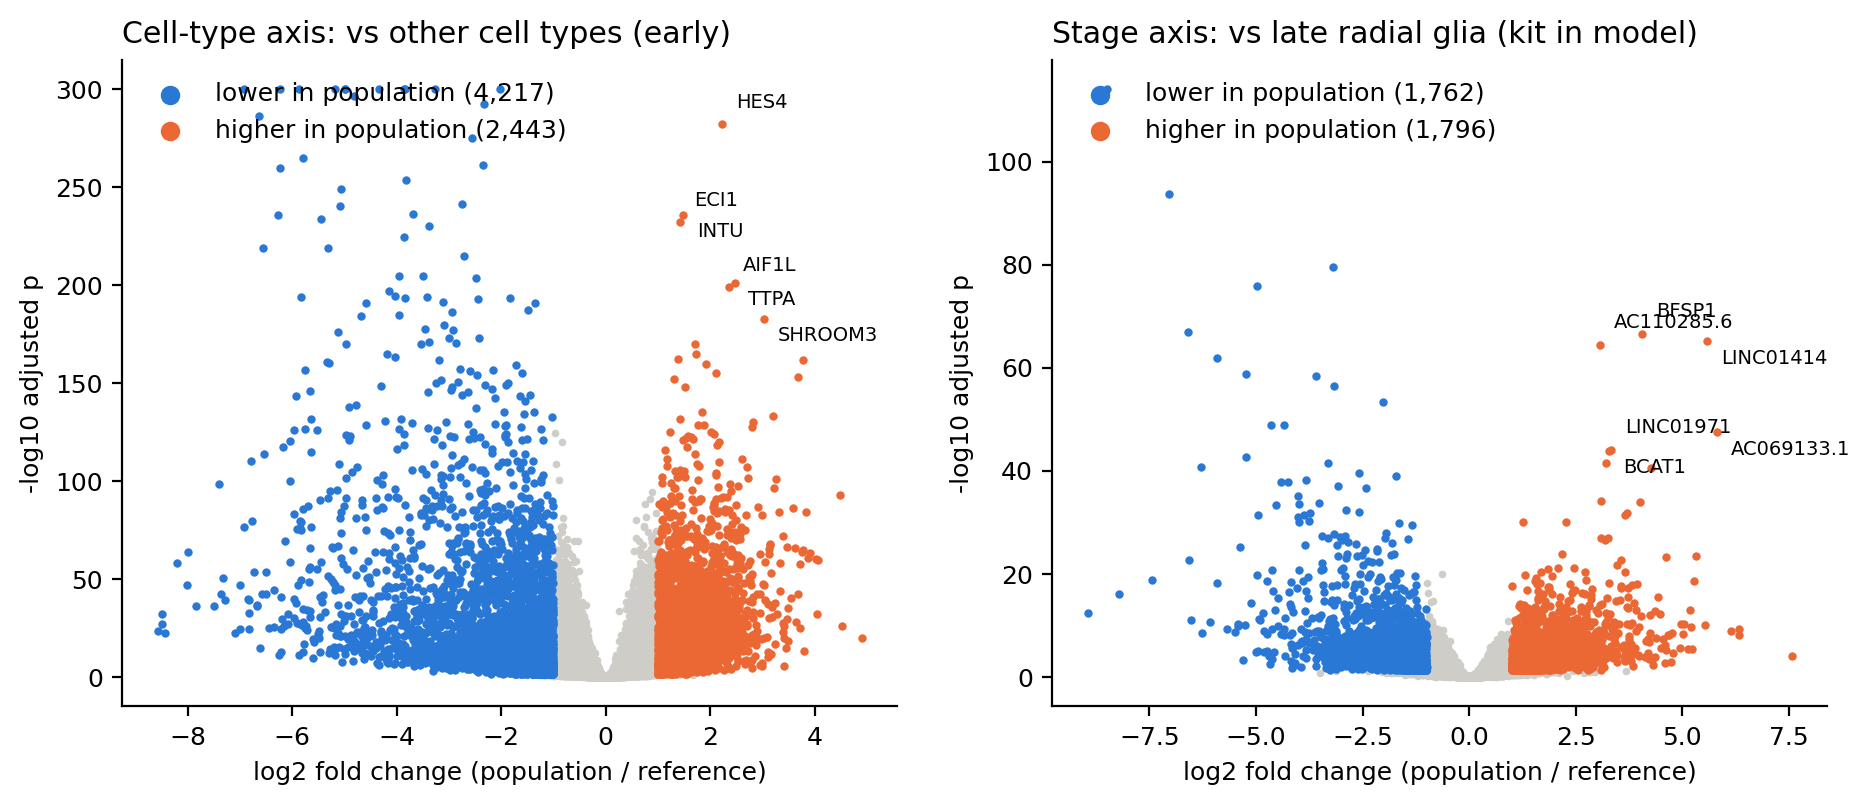

In [6]:
# Orange = up in the population, blue = down, grey = not significant or small change.
# The six genes with the highest statistic are labelled, staggered up and down so they do not overlap.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, res, title in [(axes[0], celltype, "Cell-type axis: vs other cell types (early)"),
                       (axes[1], stage, "Stage axis: vs late radial glia (kit in model)")]:
    res = res.dropna(subset=["padj"])
    y = -np.log10(res["padj"].clip(lower=1e-300))  # clip so padj = 0 does not give infinity
    down = (res["padj"] < PADJ) & (res["log2FoldChange"] <= -LFC)
    ax.scatter(res["log2FoldChange"], y, s=3, color="#cfcdc8", rasterized=True)
    ax.scatter(res.loc[down, "log2FoldChange"], y[down], s=4, color="#2a78d6", label=f"lower in population ({down.sum():,})")
    ax.scatter(res.loc[res["up"], "log2FoldChange"], y[res["up"]], s=4, color="#eb6834",
               label=f"higher in population ({res['up'].sum():,})")
    for i, (gene_id, row) in enumerate(res[res["up"]].head(6).iterrows()):
        ax.annotate(row["gene"], (row["log2FoldChange"], y[gene_id]), xytext=(5, 6 - 14 * (i % 2)),
                    textcoords="offset points", fontsize=7)
    ax.set_xlabel("log2 fold change (population / reference)")
    ax.set_ylabel("-log10 adjusted p")
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left", markerscale=3)
save(fig, "07_volcano")

**Reading the figure**

- **Cell-type axis (left):** many genes with very small p-values on both sides. The population differs strongly
  from neurons, glia and other cell types, which is expected for a progenitor state. 2,443 genes higher,
  4,217 lower.
- **Stage axis (right):** fewer and weaker differences (1,796 higher, 1,762 lower) and weaker significance
  overall (the y axis reaches about 100 instead of 300). This comparison has fewer samples (11 vs 5) and compares the same lineage, so differences are
  smaller. Several top genes are lncRNAs (LINC..., AC...) and early-development genes such as SALL4 and
  LIN28B-AS1.
- Two labels in the right panel overlap slightly (BFSP1 and AC110285.6). It is a cosmetic issue only.

## Figure: fold change on both axes

**What this cell does**

- One dot per gene tested on both axes: x = log2 FC on the cell-type axis, y = log2 FC on the stage axis.
- Colours by category: grey neither, blue cell type only, green stage only, orange both.
- The dashed lines are at log2 FC = 1 on each axis. Orange genes sit in the upper right corner beyond both lines.
- `named`: the top "both" genes, skipping unnamed lncRNAs (names starting with AC, AL, AP or LINC) so the
  labels show genes a reader can look up. `str.match` with the pattern `^(A[CLP]\d|LINC)` finds those names.
- The legend is placed outside the plot (`bbox_to_anchor=(1, 1)`) so it does not hide dots.

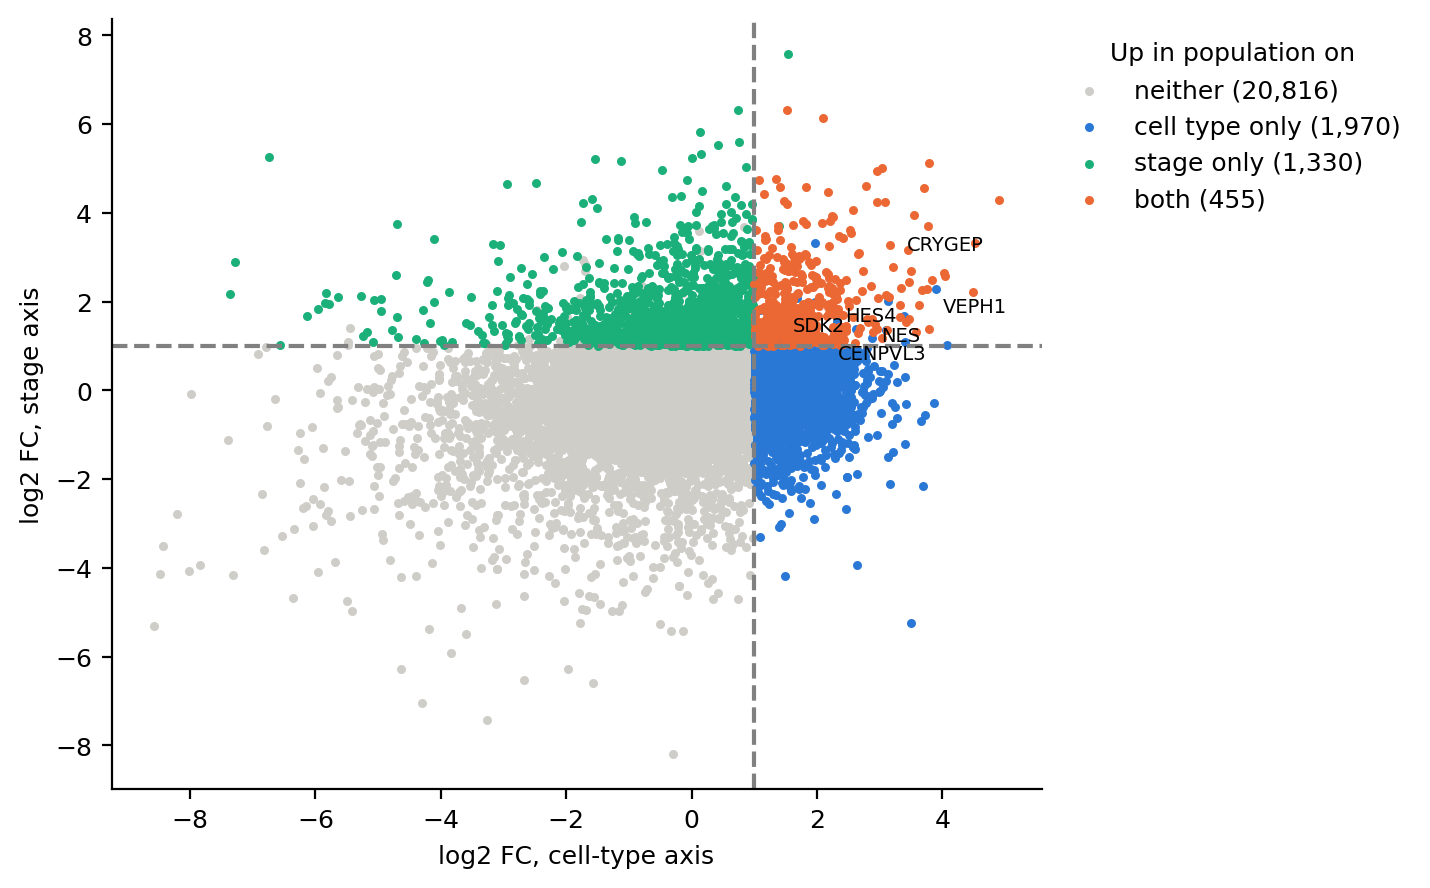

In [7]:
# Top-right corner beyond both dashed lines = genes specific to both cell type and stage
colors = {"neither": "#cfcdc8", "cell type only": "#2a78d6", "stage only": "#1baf7a", "both": "#eb6834"}
fig, ax = plt.subplots(figsize=(6, 5))
for cat, color in colors.items():
    d = axes2[axes2["category"] == cat]
    ax.scatter(d["log2FoldChange_celltype"], d["log2FoldChange_stage"], s=5, color=color, rasterized=True,
               label=f"{cat} ({len(d):,})")
named = both[~both["gene"].str.match(r"^(A[CLP]\d|LINC)")]  # skip unnamed lncRNAs when labelling
for i, (gene_id, row) in enumerate(named.head(6).iterrows()):
    ax.annotate(row["gene"], (row["log2FoldChange_celltype"], row["log2FoldChange_stage"]),
                xytext=(5, 6 - 14 * (i % 2)), textcoords="offset points", fontsize=7)
ax.axvline(LFC, color="grey", linestyle="--")
ax.axhline(LFC, color="grey", linestyle="--")
ax.set_xlabel("log2 FC, cell-type axis")
ax.set_ylabel("log2 FC, stage axis")
ax.legend(title="Up in population on", loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "07_markers_both_axes")

**Reading the figure**

- The two axes are only weakly related: many genes are up on one axis but not the other. This is why the brief
  asks for both. A gene that separates the population from neurons is not necessarily one that separates it
  from older radial glia.
- The orange corner (455 genes) holds the genes specific to this cell type at this stage, such as HES4, SDK2,
  VEPH1, NES and TIMELESS.
- A few labels in the corner sit close together. It is a cosmetic issue only.

## Conclusion of step 07 (answer to question 2)

1. **Cell-type axis:** 2,443 genes mark the population against other early cell types, led by HES4 (a Notch
   target) and SHROOM3, each found in about 85% of population cells.
2. **Stage axis:** 1,796 genes mark it against late radial glia, including early-development genes (SALL4,
   LIN28B-AS1, LIN28A, BCAT1) and many lncRNAs.
3. **Both:** 455 genes, including HES4, SDK2, VEPH1, NES and TIMELESS.
4. The three query genes split across the axes: TTYH1 is a cell-type marker, LIN28A a stage marker and NES
   marks both.
5. **Caveat on the stage axis:** the late reference has only 5 samples, one of them v2. The kit is in the
   model, but step 02 showed the kit effect is only partly the same at late ages. Stage markers with small fold
   changes should be read with care.